# Skin lesion model comparison

This notebook runs the same five patient-grouped folds for every model. I use
the missingness-only result to see how much the recording pattern can
predict on its own. Then I compare two versions of the same image and clinical
model with more fields hidden during evaluation.

[PAD-UFES-20](https://doi.org/10.1016/j.dib.2020.106221) ·
[ResNet-18 weights and image transforms](https://docs.pytorch.org/vision/0.23/models/generated/torchvision.models.resnet18.html) ·
[Clinical and image feature fusion](https://doi.org/10.1177/11769351251349891) ·
[Related missing metadata work](https://doi.org/10.1109/JBHI.2025.3612837)

## Check the data

The notebook expects the original metadata CSV and the extracted PNG files.
I leave blanks and `UNK` as missing, then fit any learned preprocessing inside
each training fold. The diagnosis is the target. IDs and biopsy status stay
outside the model inputs.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import torch
from IPython.display import Image

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.data import load_metadata
from src.images import image_paths
from src.train import run_experiments

data = load_metadata(root / "data/metadata.csv")
paths = image_paths(root / "data/images", data["img_id"])
print(f"{len(paths)} matched images and {data['patient_id'].nunique()} patients")
display(data["diagnostic"].value_counts().sort_index().rename("images").to_frame())

2298 matched images and 1373 patients


,images
diagnostic,
ACK,730
BCC,845
MEL,52
NEV,244
SCC,192
SEK,235


## Train and compare

The pretrained ResNet-18 stays frozen. The script extracts one feature vector
per image and caches it, so the heads can reuse the same vectors across folds.
For the masking comparison, I hide 25% of available fields on average during
training, resampling each epoch. At evaluation, the same fields are hidden for
both fusion models. The 0% condition still includes the original missing values.

The first run will take longer because it has to process the images. The
script saves the loss history, held-out predictions, metrics, and demo models.

In [2]:
torch.set_num_threads(4)
metrics = run_experiments(root)

overall = metrics[metrics["metric"].isin(["balanced_accuracy", "macro_f1"])]
display(overall.pivot(index="condition", columns="metric", values="estimate").round(3))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Andrew Dodds/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Extracting ResNet-18 features on cpu
  320/2298 images
  640/2298 images
  960/2298 images
  1280/2298 images
  1600/2298 images
  1920/2298 images
  2240/2298 images
  2298/2298 images
Fold 1: 1838 training images, 460 held out
  image_only: loss 1.735 -> 0.752
  full_metadata: loss 1.712 -> 0.642
  demographics: loss 1.751 -> 1.222
  fusion_standard: loss 1.616 -> 0.381
  fusion_masked: loss 1.639 -> 0.465
Fold 2: 1838 training images, 460 held out
  image_only: loss 1.616 -> 0.758
  full_metadata: loss 1.692 -> 0.597
  demographics: loss 1.752 -> 1.217
  fusion_standard: loss 1.561 -> 0.361
  fusion_masked: loss 1.576 -> 0.472
Fold 3: 1839 training images, 459 held out
  image_only: loss 1.693 -> 0.742
  full_metadata: loss 1.710 -> 0.631
  demographics: loss 1.745 -> 1.225
  fusion_standard: loss 1.646 -> 0.370
  fusion_masked: loss 1.662 -> 0.491
Fold 4: 1838 training images, 460 held out
  image_only: loss 1.718 -> 0.773
  full_metadata: loss 1.677 -> 0.643
  demographics: loss 1

metric,balanced_accuracy,macro_f1
condition,,
demographics,0.458,0.333
full_metadata,0.665,0.607
fusion_masked_0,0.701,0.675
fusion_masked_25,0.665,0.651
fusion_masked_50,0.611,0.593
fusion_standard_0,0.694,0.680
fusion_standard_25,0.593,0.576
fusion_standard_50,0.455,0.399
image_only,0.533,0.510


## Held-out results

I bootstrap whole patients 2,000 times from the held-out predictions.
The intervals describe uncertainty in these predictions. The models are
already fitted before the bootstrap runs.

,estimate,ci_low,ci_high
condition,,,
majority_class,0.167,0.167,0.167
missingness_only,0.269,0.261,0.277
image_only,0.533,0.501,0.567
full_metadata,0.665,0.628,0.698
demographics,0.458,0.422,0.496
fusion_standard_0,0.694,0.663,0.726
fusion_masked_0,0.701,0.670,0.729
fusion_standard_25,0.593,0.562,0.623
fusion_masked_25,0.665,0.633,0.696


,comparison,metric,difference,ci_low,ci_high
0,missingness_vs_majority,balanced_accuracy,0.103,0.094,0.110
1,missingness_vs_majority,macro_f1,0.130,0.121,0.138
2,masked_minus_standard_0,balanced_accuracy,0.006,-0.010,0.025
3,masked_minus_standard_0,macro_f1,-0.006,-0.021,0.010
4,masked_minus_standard_25,balanced_accuracy,0.072,0.048,0.097
5,masked_minus_standard_25,macro_f1,0.075,0.052,0.100
6,smaller_drop_25,balanced_accuracy,0.066,0.038,0.094
7,smaller_drop_25,macro_f1,0.081,0.055,0.107
8,masked_minus_standard_50,balanced_accuracy,0.156,0.125,0.186
9,masked_minus_standard_50,macro_f1,0.194,0.159,0.225


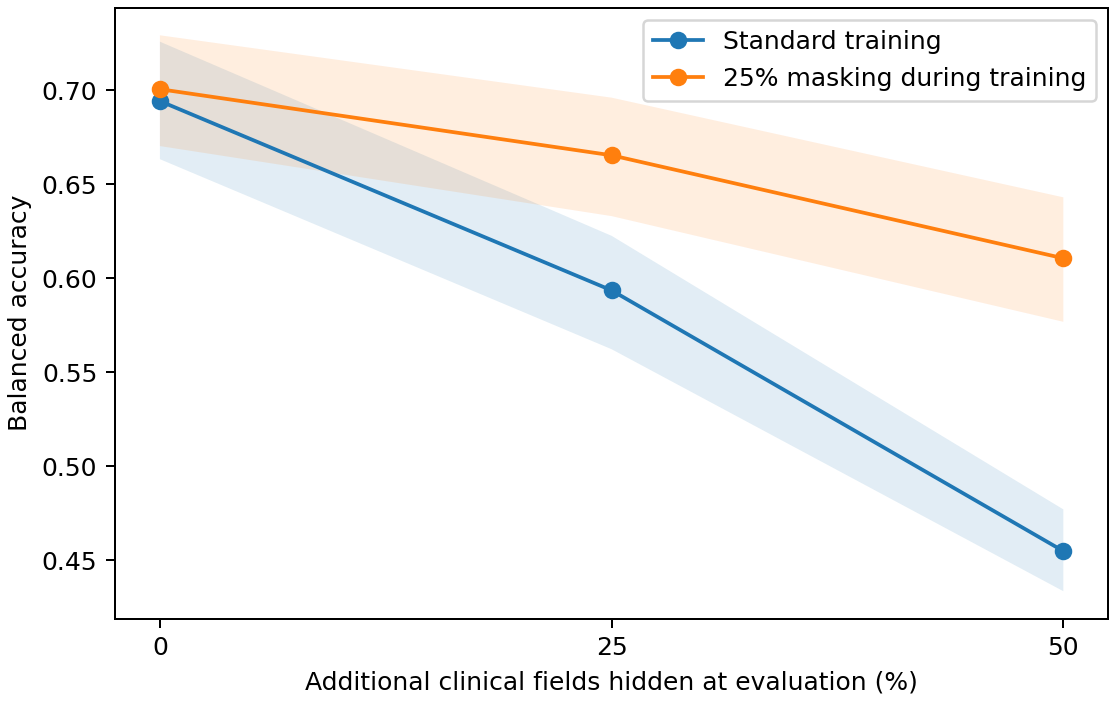

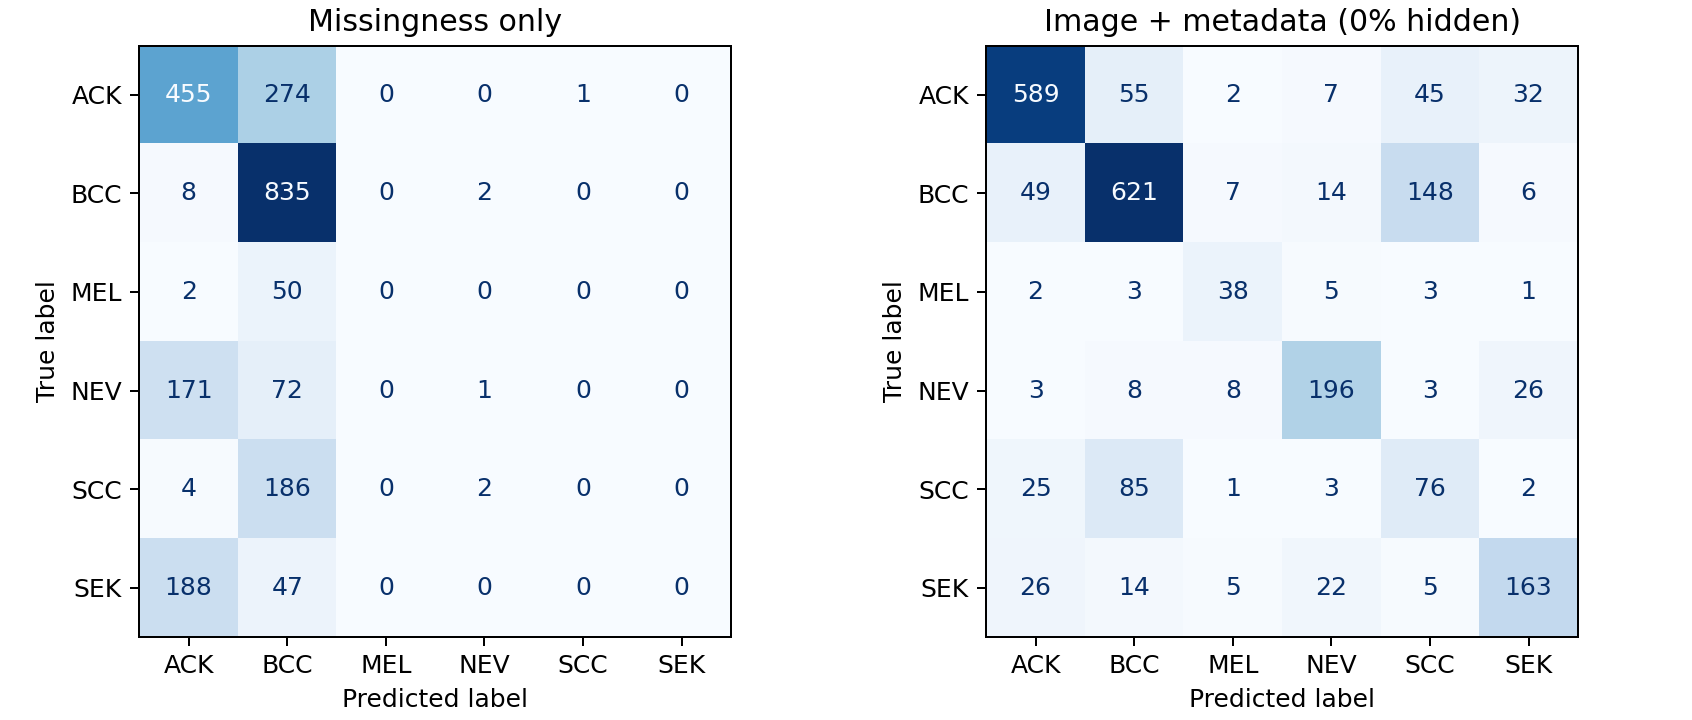

In [3]:
results = root / "results"
balanced = metrics[metrics["metric"] == "balanced_accuracy"]
display(balanced.drop(columns="metric").set_index("condition").round(3))
display(pd.read_csv(results / "prototype_paired_differences.csv").round(3))
display(Image(filename=str(results / "masking_comparison.png")))
display(Image(filename=str(results / "prototype_confusion_matrices.png")))

In [4]:
predictions = pd.read_csv(root / "data/processed/prototype_predictions.csv")
columns = ["fold", "diagnostic", "image_only", "fusion_standard_50", "fusion_masked_50"]
display(predictions[columns].head())

,fold,diagnostic,image_only,fusion_standard_50,fusion_masked_50
0,2,NEV,NEV,NEV,NEV
1,5,BCC,ACK,ACK,BCC
2,5,ACK,ACK,ACK,ACK
3,5,ACK,BCC,ACK,ACK
4,2,BCC,SCC,SEK,SCC
